# 46. Incremental information of the spectral feature for pre-onset warning (BTC spot)

I test whether the existing spectral feature `z_hs` adds information before the 1% onset beyond volatility (`z_vol`) and the taker sell ratio (`tsr`). To do so I compare a feature ablation with a change of training label, using four logistic models:

| Model | Features | 2021 target |
|:--|:--|:--|
| `Breach_M0` | z_vol, tsr | breach 30–240 minutes ahead (notebook 16 M0 baseline) |
| `Breach_M0_HS` | z_vol, tsr, z_hs | same breach target |
| `Onset_M0` | z_vol, tsr | 1% onset of an eventual crash 30–240 minutes ahead |
| `Onset_M0_HS` | z_vol, tsr, z_hs | same onset target |

- Data and periods: BTC spot one-minute caches. I fit the models on 2021, calibrate thresholds on 2022 without outcomes and evaluate on 2023 to April 2026 as an exploratory analysis.
- Alert budget: 20 alerts per month, 240 per year and a 240-minute cooldown; I tune nothing on evaluation results.
- Metrics: pre-onset event catches under breach-anchored and onset-anchored judging windows, actual alerts issued, and AUC and pre-onset AUC, including comparisons within volatility deciles.
- Status: this is an exploratory, post hoc first screen, not a confirmatory or independent out-of-sample test, and the new models are not part of the OSF registration.
- I fixed the screening hurdle before reading the output and recorded it in `46_SPEC.json`.
- Results folder: `spectral_onset_incremental_v1`.

In [1]:
from pathlib import Path
import sys, subprocess, json, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

try:
    import pyarrow
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'pyarrow'])

try:
    from numba import njit
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'numba'])
    from numba import njit

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not in Colab. Configure ROOT manually to run with local files.')

ROOT = Path('/content/drive/MyDrive/btc_lead_cost_results_77months_spot')
CACHE = ROOT/'cache'
OUT = ROOT/'spectral_onset_incremental_v1'
OUT.mkdir(parents=True, exist_ok=True)
NS = 60*10**9
T0 = pd.Timestamp('2021-01-01', tz='UTC').value
T1 = pd.Timestamp('2022-01-01', tz='UTC').value
T2 = pd.Timestamp('2023-01-01', tz='UTC').value
E0 = pd.Timestamp('2023-01-01', tz='UTC').value
E1 = pd.Timestamp('2026-05-01', tz='UTC').value
LEAD_MIN, LEAD_MAX = 30, 240
COOLDOWN = 240
BUDGET_MONTH, BUDGET_YEAR = 20, 240
SPEC = {'notebook':'46', 'status':'exploratory_posthoc', 'train':'2021', 'threshold_calibration':'2022_unlabeled',
        'evaluation':'2023-01 through 2026-04', 'feature':'z_hs existing FFT spectral feature',
        'models':['Breach_M0','Breach_M0_HS','Onset_M0','Onset_M0_HS'],
        'lead_minutes':[30,240], 'monthly_cap':20, 'annual_cap':240, 'cooldown_minutes':240,
        'evaluation_primary':'breach-anchored pre-onset catches at H=240',
        'evaluation_secondary':'onset-anchored pre-onset catches; pre-onset AUC and within-RV-decile AUC; H=1440',
        'random_seed':17, 'no_holdout_or_prospective_inputs': True,
        'screening_thresholds_posthoc':{'auc_gain':0.02,'catch_gain_per_100_alerts':0.5}}
(OUT/'46_SPEC.json').write_text(json.dumps(SPEC,indent=2))
print('Results:', OUT)


Mounted at /content/drive
Results: /content/drive/MyDrive/btc_lead_cost_results_77months_spot/spectral_onset_incremental_v1


## 1. Data and the existing event rule

I use the frozen spot parquet caches and the price-only event definition; future onset and breach times serve only as training labels, never as input features. I condition onset labels on an eventual 4% breach (event prediction, not prediction of every 1% dip), and the 2021 training period ends 245 minutes before 2022 so that no label spans the boundary.

In [2]:
for p in [CACHE/'BTCUSDT_1m_regularized.parquet', CACHE/'btc_signals_1m.parquet', CACHE/'DATA_SOURCE.json']:
    if not p.is_file():
        raise FileNotFoundError(f'Required frozen spot cache missing: {p}')
source = json.loads((CACHE/'DATA_SOURCE.json').read_text())
assert source.get('venue')=='spot', 'The cache must be BTC SPOT; no futures substitute.'
px = pd.read_parquet(CACHE/'BTCUSDT_1m_regularized.parquet').sort_index()
sg = pd.read_parquet(CACHE/'btc_signals_1m.parquet', columns=['z_vol','tsr','z_hs']).sort_index()
for d in (px, sg):
    assert isinstance(d.index, pd.DatetimeIndex) and d.index.tz is not None
    d.index = d.index.tz_convert('UTC')
assert px.index.equals(sg.index), 'Price/signal minute indexes differ'
T = px.index.asi8
assert np.all(np.diff(T)==NS), 'Index is not a complete one-minute grid'
close = px.close.to_numpy(dtype=float)
volume = px.volume.to_numpy(dtype=float)
X = sg[['z_vol','tsr','z_hs']].to_numpy(dtype=float)
valid = (np.isfinite(close)&(close>0)&np.isfinite(volume)&(volume>0)&
         np.isfinite(X).all(axis=1)&(X[:,1]>=0)&(X[:,1]<=1))
print('rows',len(T),'train valid',int((valid&(T>=T0)&(T<T1)).sum()),'eval valid',int((valid&(T>=E0)&(T<E1)).sum()))

def price_only_catalog(close,volume,index,H=240,decline=.04,sustain=5,refractory=1440):
    c=np.asarray(close,dtype=np.float64)
    obs=np.isfinite(c)&(c>0)&np.isfinite(volume)&(np.asarray(volume)>0)
    prior=pd.Series(np.where(obs,c,np.nan)).rolling(H,min_periods=H).max().shift(1).to_numpy()
    raw=obs & np.isfinite(prior) & (c<=(1-decline)*prior)
    fresh=raw & ~np.r_[False,raw[:-1]]
    rows=[];last_confirm=-10**12
    for i in np.flatnonzero(fresh):
        if i+sustain>len(c) or i-last_confirm<refractory: continue
        threshold=(1-decline)*prior[i]
        if not(obs[i:i+sustain].all() and np.all(c[i:i+sustain]<=threshold)):continue
        if i-H<0 or not obs[i-H:i].all():continue
        prev=c[i-H:i];peak_i=int(i-H+np.argmax(prev))
        if peak_i<=last_confirm:continue
        onset_candidates=np.flatnonzero(c[peak_i+1:i+1]<=.99*c[peak_i])
        if not len(onset_candidates):continue
        oi=int(peak_i+1+onset_candidates[0])
        rows.append({'event_id':len(rows)+1,'peak_utc':index[peak_i],
                     'onset_1pct_utc':index[oi],'breach_utc':index[i],
                     'confirmed_utc':index[i+sustain-1],
                     'onset_to_breach_minutes':i-oi})
        last_confirm=i+sustain-1
    if not rows: raise RuntimeError('Event catalog empty')
    return pd.DataFrame(rows)

CAT = {h:price_only_catalog(close,volume,px.index,H=h) for h in (240,1440)}
EVAL = {h:CAT[h].loc[(CAT[h].breach_utc.astype('int64')>=E0+LEAD_MAX*NS)&
                             (CAT[h].breach_utc.astype('int64')<E1)].copy().reset_index(drop=True)
        for h in (240,1440)}
# Onset-anchored evaluation needs a complete onset-240 ... onset-30 window.
EVAL_ON = {h: EVAL[h].loc[EVAL[h].onset_1pct_utc.astype('int64') >= E0 + LEAD_MAX*NS].reset_index(drop=True)
           for h in (240,1440)}
# Mandatory guard against the reference 4-hour development event count
assert len(EVAL[240])==83, f'Expected 83 development events at H=240, found {len(EVAL[240])}'
assert len(EVAL[1440])==218, f'Expected 218 events at H=1440, found {len(EVAL[1440])}'
# Optional: exact timestamp comparison with notebook 2
ref = ROOT/'event_definition_eligibility_audit'/'price_only_event_catalog.csv'
if ref.is_file():
    q = pd.read_csv(ref)
    for c in ('peak_utc','onset_1pct_utc','breach_utc','confirmed_utc'):
        a = pd.to_datetime(q[c],utc=True).astype('int64').to_numpy()
        b = CAT[240][c].astype('int64').to_numpy()
        assert np.array_equal(a,b), f'Notebook 2 mismatch for {c}'
    print('PASS: notebook-2 event timestamps reproduced.')

# Labels from the next qualifying event timestamp (same searchsorted convention as notebook 41).
def future_label(T, events_ns):
    z=np.sort(np.asarray(events_ns,dtype=np.int64))
    positions=np.searchsorted(z,T+LEAD_MIN*NS,side='left')
    y=np.zeros(len(T),dtype=np.int8)
    good=positions<len(z)
    y[good]=(z[positions[good]]<=T[good]+LEAD_MAX*NS).astype(np.int8)
    return y

cat4=CAT[240]
y_breach = future_label(T,cat4.breach_utc.astype('int64').to_numpy())
y_onset = future_label(T,cat4.onset_1pct_utc.astype('int64').to_numpy())
# No retrospective classification rule is used as a runtime signal. During onset training,
# remove confirmed-event in-progress minutes from the negative training examples.
in_progress = np.zeros(len(T),bool)
for e in cat4.itertuples(index=False):
    a=np.searchsorted(T,e.onset_1pct_utc.value,'left')
    b=np.searchsorted(T,e.confirmed_utc.value,'right')
    in_progress[a:b]=True
TRAIN = valid &(T>=T0)&(T<T1-(LEAD_MAX+5)*NS)
TRAIN_ONSET = TRAIN & ~in_progress
CAL = valid &(T>=T1)&(T<T2)
DEV = valid &(T>=E0)&(T<E1-(LEAD_MAX+5)*NS)
print('2021 breach positive minutes:',int(y_breach[TRAIN].sum()))
print('2021 onset positive minutes:',int(y_onset[TRAIN_ONSET].sum()))
if not (y_breach[TRAIN].sum()>50 and y_onset[TRAIN_ONSET].sum()>50):
    raise RuntimeError('Insufficient training positives: inspect event labels and cache.')


rows 3329280 train valid 524332 eval valid 1750857
PASS: notebook-2 event timestamps reproduced.
2021 breach positive minutes: 18779
2021 onset positive minutes: 18771


## 2. Four frozen logistic models with matched features and targets

The logistic baseline follows notebook 16 (`StandardScaler + LogisticRegression(C=0.2, class_weight="balanced")`), and I compute its scores from trailing-only `z_vol`, `tsr` and the existing spectral feature `z_hs`.

In [3]:
def new_logit():
    return make_pipeline(StandardScaler(),LogisticRegression(C=0.2,class_weight='balanced',
                         max_iter=400,solver='lbfgs',random_state=17))

MODELS = {}
MODEL_SPEC = {
 'Breach_M0':([0,1],TRAIN,y_breach),
 'Breach_M0_HS':([0,1,2],TRAIN,y_breach),
 'Onset_M0':([0,1],TRAIN_ONSET,y_onset),
 'Onset_M0_HS':([0,1,2],TRAIN_ONSET,y_onset),
}
for name,(cols,m,yy) in MODEL_SPEC.items():
    print('Training', name,'N=',int(m.sum()),'positive=',int(yy[m].sum()),flush=True)
    MODEL = new_logit()
    MODEL.fit(X[m][:,cols], yy[m])
    MODELS[name]=(MODEL,cols)

# Verify the reproduced unmodified M0 model with notebook 16 if present.
frozen = ROOT/'methods_definitions_v1'/'METHODS_FROZEN.json'
if frozen.is_file():
    f=json.loads(frozen.read_text())
    cfg=f['configs']['M0_VF_logit|4pct']
    m=MODELS['Breach_M0'][0]
    assert np.allclose(m[-1].coef_.ravel(),cfg['coef'],rtol=1e-6,atol=1e-9), 'Frozen M0 coefficient mismatch'
    assert np.isclose(m[-1].intercept_[0],cfg['intercept'],rtol=1e-6,atol=1e-9), 'Frozen M0 intercept mismatch'
    print('PASS: M0 model coefficients / intercept reproduced')

# Score only 2022 calibration and 2023-2026 exploratory samples.
SCORE={}
mask_pred = CAL|DEV
for name,(model,cols) in MODELS.items():
    sc=np.full(len(T),np.nan,dtype=np.float64)
    sc[mask_pred]=model.predict_proba(X[mask_pred][:,cols])[:,1]
    SCORE[name]=sc
print('Model scores computed. No holdout/backcast/prospective result files accessed.')


Training Breach_M0 N= 524087 positive= 18779
Training Breach_M0_HS N= 524087 positive= 18779
Training Onset_M0 N= 510415 positive= 18771
Training Onset_M0_HS N= 510415 positive= 18771
PASS: M0 model coefficients / intercept reproduced
Model scores computed. No holdout/backcast/prospective result files accessed.


## 3. Threshold calibration on unlabeled 2022 data and fixed alert scheduler

All candidates share the same threshold-selection algorithm and calendar scheduler. I report actual alert counts, because a model that sends fewer alerts is not equivalent at a fixed budget.

In [4]:
@njit(cache=False)
def calendar_core(t,elig,years,months,B,cap,cooldown_ns):
    out=np.empty(len(t),dtype=np.int64)
    n=0; month_count=0; year_count=0; last_m=-1; last_y=-1; last=-(2**62)
    for i in range(len(t)):
        if not elig[i]: continue
        yr=years[i]; mo=months[i]; ti=t[i]
        if yr!=last_y: year_count=0; last_y=yr
        if mo!=last_m: month_count=0; last_m=mo
        if month_count>=cap or year_count>=B or ti-last<cooldown_ns: continue
        out[n]=ti;n+=1;month_count+=1;year_count+=1;last=ti
    return out[:n].copy()

def scheduler(time_ns,score,threshold):
    tm=pd.to_datetime(time_ns,utc=True)
    yrs=np.asarray(tm.year,dtype=np.int64)
    months=np.asarray(tm.year*12+tm.month,dtype=np.int64)
    e=np.asarray(np.isfinite(score)&(score>=threshold),dtype=np.bool_)
    return calendar_core(np.asarray(time_ns,np.int64),e,yrs,months,BUDGET_YEAR,BUDGET_MONTH,COOLDOWN*NS)

def score_grid(sc):
    Q=np.unique(np.r_[0.,np.linspace(.10,.995,33),.997,.999,.9999,1.])
    return np.unique(np.r_[np.nextafter(sc.min(),-np.inf),np.quantile(sc,Q),np.nextafter(sc.max(),np.inf)])

def calibrate(time_ns,sc):
    rows=[]
    for th in score_grid(sc):
        count=len(scheduler(time_ns,sc,th))
        rows.append((float(th),count,int(np.count_nonzero(sc>=th))))
    d=pd.DataFrame(rows,columns=['threshold','cal_alerts','raw_candidates'])
    row=d[d.cal_alerts==d.cal_alerts.max()].sort_values('raw_candidates').iloc[0]
    return float(row.threshold),int(row.cal_alerts),d

T_CAL=T[CAL];T_DEV=T[DEV]
THR={}; ALARMS={}; CAL_COUNTS={}
for name in MODELS:
    thr,ncal,_=calibrate(T_CAL,SCORE[name][CAL])
    THR[name]=thr;CAL_COUNTS[name]=ncal
    ALARMS[name]=scheduler(T_DEV,SCORE[name][DEV],thr)
    print(f'{name:14s} 2022 cal alerts={ncal:3d}  threshold={thr:.6g}  development alerts={len(ALARMS[name])}')
assert all(len(x)<=40*20 for x in ALARMS.values()),'Exceeded maximum 40-month 20-per-month budget'


Breach_M0      2022 cal alerts=240  threshold=0.669899  development alerts=800
Breach_M0_HS   2022 cal alerts=240  threshold=0.671414  development alerts=800
Onset_M0       2022 cal alerts=240  threshold=0.58844  development alerts=800
Onset_M0_HS    2022 cal alerts=240  threshold=0.590193  development alerts=800


## 4. Event-level pre-onset catches under two judging windows

The primary window is breach-anchored, `[breach-240, breach-30]`, and I count only alerts before onset. The secondary window `[onset-240, onset-30]`, which I restrict to events with a complete onset-anchored window, removes the structural impossibility of catching a slow crash in the breach-anchored window but is a different task and endpoint. At H=1440 I run an exploratory diagnostic of the same differences.

In [5]:
def event_catches(events, alerts, anchor='breach'):
    alert=np.asarray(alerts,dtype=np.int64)
    rows=[]
    for e in events.itertuples(index=False):
        on=e.onset_1pct_utc.value;b=e.breach_utc.value
        anchor_ns=on if anchor=='onset' else b
        lo=anchor_ns-LEAD_MAX*NS; hi=anchor_ns-LEAD_MIN*NS
        l=np.searchsorted(alert,lo,side='left')
        r=np.searchsorted(alert,hi,side='right')
        eligible=alert[l:r]
        good=eligible[eligible<on]
        rows.append((e.event_id,len(good)>0,(on-int(good[0]))/NS if len(good) else np.nan))
    return pd.DataFrame(rows,columns=['event_id','hit','lead_to_onset_minutes'])

rows=[];HITS={}
for h in (240,1440):
    for name in MODELS:
        for anchor in ('breach','onset'):
            E = EVAL_ON[h] if anchor=='onset' else EVAL[h]
            hit=event_catches(E,ALARMS[name],anchor)
            HITS[(h,name,anchor)]=hit
            n=len(ALARMS[name]);k=int(hit.hit.sum())
            rows.append({'H':h,'model':name,'anchor':anchor,'events':len(E),
                         'alerts':n,'pre_catches':k,'pre_recall':k/len(E),
                         'pre_catches_per_100_alerts':100*k/n if n else np.nan,
                         'median_lead_minutes':hit.lead_to_onset_minutes.median(),
                         '2022_calibration_alerts':CAL_COUNTS[name]})
RESULTS=pd.DataFrame(rows)
from IPython.display import display
display(RESULTS)


,H,model,anchor,events,alerts,pre_catches,pre_recall,pre_catches_per_100_alerts,median_lead_minutes,2022_calibration_alerts
0,240,Breach_M0,breach,83,800,22,0.265060,2.750,25.0,240
1,240,Breach_M0,onset,83,800,15,0.180723,1.875,72.0,240
2,240,Breach_M0_HS,breach,83,800,18,0.216867,2.250,42.5,240
3,240,Breach_M0_HS,onset,83,800,13,0.156627,1.625,64.0,240
4,240,Onset_M0,breach,83,800,15,0.180723,1.875,39.0,240
5,240,Onset_M0,onset,83,800,14,0.168675,1.750,66.5,240
6,240,Onset_M0_HS,breach,83,800,15,0.180723,1.875,39.0,240
7,240,Onset_M0_HS,onset,83,800,11,0.132530,1.375,69.0,240
8,1440,Breach_M0,breach,218,800,5,0.022936,0.625,22.0,240
9,1440,Breach_M0,onset,218,800,30,0.137615,3.750,111.5,240


## 5. AUC, volatility stratification and paired descriptive event bootstrap

At each H all models share the same negatives (development minutes outside the breach-anchored event windows); `auc_pre` uses only pre-onset positives, and `auc_pre_within_rv_decile` compares positives and negatives only within the same decile of trailing 24-hour realized volatility. I treat the results as descriptive, since I have inspected this sample many times.

In [6]:
def encoded_breach_labels(times,events):
    # 0=negative, 1=pre-onset positive, 2=in-progress positive
    b=events.breach_utc.astype('int64').to_numpy()
    o=events.onset_1pct_utc.astype('int64').to_numpy()
    ix=np.searchsorted(b,times+LEAD_MIN*NS,'left')
    code=np.zeros(len(times),np.int8)
    k=ix<len(b)
    ps=k.copy()
    ps[k]=b[ix[k]]<=times[k]+LEAD_MAX*NS
    code[ps]=np.where(times[ps]<o[ix[ps]],1,2)
    return code

# Evaluate with valid scores on the same minute index for every model
LOG_RETURN=np.log(pd.Series(np.where(np.isfinite(close)&(close>0),close,np.nan))).diff()
RV=LOG_RETURN.rolling(1440,min_periods=720).std().to_numpy()
COM=DEV & np.isfinite(RV)
for v in SCORE.values():COM &= np.isfinite(v)
RVD=RV[COM]
q=np.quantile(RVD,np.arange(.1,1.,.1))
DEC=np.searchsorted(q,RVD,side='right')
T_COM=T[COM]

def auc_score(y,score):
    if len(np.unique(y))<2:return np.nan
    return float(roc_auc_score(y,score))

def within_decile_auc(pos,neg,s,dec):
    vals=[];w=[]
    for d in range(10):
        p=pos&(dec==d); n=neg&(dec==d)
        if p.sum() and n.sum():
            vals.append(auc_score(np.r_[np.ones(p.sum()),np.zeros(n.sum())],np.r_[s[p],s[n]]))
            w.append(int(p.sum())*int(n.sum()))
    return float(np.average(vals,weights=w)) if w else np.nan

AUC_ROWS=[]
for h in (240,1440):
    enc=encoded_breach_labels(T_COM,EVAL[h])
    neg=enc==0;pre=enc==1;progress=enc==2
    print('H',h,'pre/minutes',int(pre.sum()),'in/minutes',int(progress.sum()))
    for name in MODELS:
        s=SCORE[name][COM]
        a1=auc_score(np.r_[np.ones(pre.sum()),np.zeros(neg.sum())],np.r_[s[pre],s[neg]])
        a2=auc_score(np.r_[np.ones(progress.sum()),np.zeros(neg.sum())],np.r_[s[progress],s[neg]])
        a3=auc_score(np.r_[np.ones((enc>0).sum()),np.zeros(neg.sum())],np.r_[s[enc>0],s[neg]])
        pi=progress.sum()/(pre.sum()+progress.sum())
        assert abs(a3-((1-pi)*a1+pi*a2))<1e-9,'Decomposition mismatch'
        aw=within_decile_auc(pre,neg,s,DEC)
        AUC_ROWS.append(dict(H=h,model=name,auc_standard=a3,auc_pre=a1,
                             auc_in_progress=a2,auc_pre_within_rv_decile=aw,pi_in=pi))
AUC_TABLE=pd.DataFrame(AUC_ROWS)
display(AUC_TABLE)

# Descriptive paired-event uncertainty (not a formal dependent-data validity theorem).
RNG=np.random.default_rng(20261146)
PAIR_ROWS=[]
comparisons=[('Breach_M0','Breach_M0_HS'),('Onset_M0','Onset_M0_HS'),('Breach_M0','Onset_M0'),('Breach_M0_HS','Onset_M0_HS')]
for h in (240,1440):
    for anchor in ('breach','onset'):
        for a,b in comparisons:
            A=HITS[(h,a,anchor)].hit.to_numpy(dtype=float)
            B=HITS[(h,b,anchor)].hit.to_numpy(dtype=float)
            n=len(A);indices=RNG.integers(0,n,size=(2000,n))
            db=np.sum(B[indices]-A[indices],axis=1)
            PAIR_ROWS.append(dict(H=h,anchor=anchor,base=a,new=b,
                base_catches=int(A.sum()),new_catches=int(B.sum()),diff_catches=int(B.sum()-A.sum()),
                event_boot_lo=float(np.percentile(db,2.5)),event_boot_hi=float(np.percentile(db,97.5)),
                base_only=int(((A==1)&(B==0)).sum()),new_only=int(((A==0)&(B==1)).sum()),
                reading='descriptive; shared development events; post hoc'))
PAIR=pd.DataFrame(PAIR_ROWS)
display(PAIR)


H 240 pre/minutes 10268 in/minutes 7245
H 1440 pre/minutes 3971 in/minutes 42027


,H,model,auc_standard,auc_pre,auc_in_progress,auc_pre_within_rv_decile,pi_in
0,240,Breach_M0,0.763270,0.672849,0.891419,0.592363,0.413693
1,240,Breach_M0_HS,0.764159,0.673237,0.893017,0.594130,0.413693
2,240,Onset_M0,0.760845,0.672647,0.885844,0.593847,0.413693
3,240,Onset_M0_HS,0.752750,0.668118,0.872695,0.588567,0.413693
4,1440,Breach_M0,0.695805,0.706812,0.694765,0.647322,0.913670
5,1440,Breach_M0_HS,0.693764,0.711659,0.692073,0.654741,0.913670
6,1440,Onset_M0,0.693186,0.705923,0.691983,0.647080,0.913670
7,1440,Onset_M0_HS,0.690894,0.692996,0.690695,0.631428,0.913670


,H,anchor,base,new,base_catches,new_catches,diff_catches,event_boot_lo,event_boot_hi,base_only,new_only,reading
0,240,breach,Breach_M0,Breach_M0_HS,22,18,-4,-8.000,-1.0,4,0,descriptive; shared development events; post hoc
1,240,breach,Onset_M0,Onset_M0_HS,15,15,0,-3.000,3.0,1,1,descriptive; shared development events; post hoc
2,240,breach,Breach_M0,Onset_M0,22,15,-7,-12.025,-3.0,7,0,descriptive; shared development events; post hoc
3,240,breach,Breach_M0_HS,Onset_M0_HS,18,15,-3,-7.000,1.0,4,1,descriptive; shared development events; post hoc
4,240,onset,Breach_M0,Breach_M0_HS,15,13,-2,-6.000,2.0,3,1,descriptive; shared development events; post hoc
5,240,onset,Onset_M0,Onset_M0_HS,14,11,-3,-7.000,0.0,3,0,descriptive; shared development events; post hoc
6,240,onset,Breach_M0,Onset_M0,15,14,-1,-5.000,3.0,3,2,descriptive; shared development events; post hoc
7,240,onset,Breach_M0_HS,Onset_M0_HS,13,11,-2,-7.000,3.0,4,2,descriptive; shared development events; post hoc
8,1440,breach,Breach_M0,Breach_M0_HS,5,3,-2,-5.000,0.0,2,0,descriptive; shared development events; post hoc
9,1440,breach,Onset_M0,Onset_M0_HS,3,4,1,0.000,3.0,0,1,descriptive; shared development events; post hoc


## 6. Saved outputs, figure and screening readout

The screen asks whether adding `z_hs`, with the target and model class unchanged, raises the 4-hour within-RV-decile pre-onset AUC by at least `+0.02` and adds at least `+0.5` pre-onset caught events per 100 alerts, without either gain coming from sending many more alerts. This is a post hoc screening hurdle, not a p-value or a confirmatory result, and I read failure of either condition as no spectral modeling contribution on these data.

,base,new,d_auc_pre_within_decile,d_pre_catches_per_100_alerts,extra_alerts,screen_hurdle_met
0,Breach_M0,Breach_M0_HS,0.001768,-0.5,0,False
1,Onset_M0,Onset_M0_HS,-0.005281,0.0,0,False


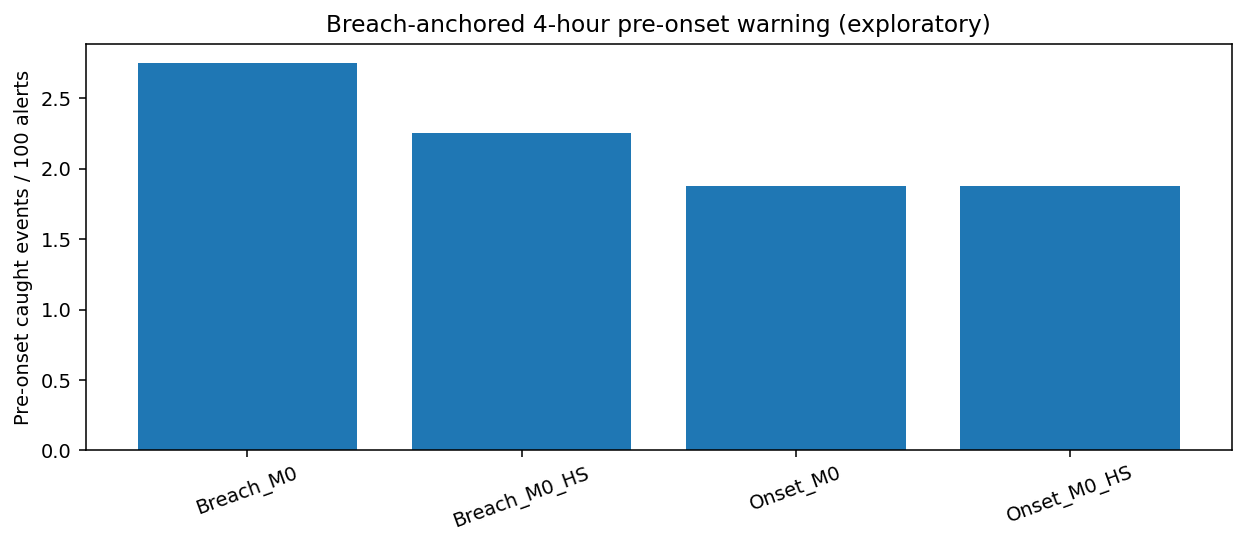

Saved in /content/drive/MyDrive/btc_lead_cost_results_77months_spot/spectral_onset_incremental_v1
Screen: an exploratory feature signal warrants further independent testing only if it meets the hurdle and does not rest on a few events. The registered prospective plan stays unchanged.


In [7]:
SPEC_PATH=OUT/'46_SPEC.json'
RESULTS.to_csv(OUT/'1_event_level.csv',index=False)
AUC_TABLE.to_csv(OUT/'2_auc.csv',index=False)
PAIR.to_csv(OUT/'3_paired_event_bootstrap_descriptive.csv',index=False)
ROW=[]
for base,new in [('Breach_M0','Breach_M0_HS'),('Onset_M0','Onset_M0_HS')]:
    b=AUC_TABLE[(AUC_TABLE.H==240)&(AUC_TABLE.model==base)].iloc[0]
    a=AUC_TABLE[(AUC_TABLE.H==240)&(AUC_TABLE.model==new)].iloc[0]
    def e(n):return RESULTS[(RESULTS.H==240)&(RESULTS.model==n)&(RESULTS.anchor=='breach')].iloc[0]
    o=e(new);q=e(base)
    dauc=float(a.auc_pre_within_rv_decile-b.auc_pre_within_rv_decile)
    dyield=float(o.pre_catches_per_100_alerts-q.pre_catches_per_100_alerts)
    ROW.append(dict(base=base,new=new,d_auc_pre_within_decile=dauc,d_pre_catches_per_100_alerts=dyield,
                    extra_alerts=int(o.alerts-q.alerts),screen_hurdle_met=(dauc>=0.02 and dyield>=0.5)))
SCREEN=pd.DataFrame(ROW)
SCREEN.to_csv(OUT/'4_screening_readout.csv',index=False)
display(SCREEN)

fig,ax=plt.subplots(figsize=(9,4),dpi=140)
plot=RESULTS[(RESULTS.H==240)&(RESULTS.anchor=='breach')].copy()
ax.bar(plot.model,plot.pre_catches_per_100_alerts)
ax.set_ylabel('Pre-onset caught events / 100 alerts')
ax.set_title('Breach-anchored 4-hour pre-onset warning (exploratory)')
ax.tick_params(axis='x',rotation=20)
plt.tight_layout()
fig.savefig(OUT/'fig46_preonset_catches.png')
plt.show()

SUMMARY={'status':'exploratory_posthoc','not_prospective_or_out_of_sample':True,
         'spec_sha256':hashlib.sha256(SPEC_PATH.read_bytes()).hexdigest(),
         'source_data_spot':True,'eval_events_4h':len(EVAL[240]),'eval_events_24h':len(EVAL[1440]),
         'calibration_alerts':CAL_COUNTS,'development_alerts':{k:len(v) for k,v in ALARMS.items()},
         'screens':SCREEN.to_dict(orient='records'),
         'note':'No look at historical backcasts or registered future results. Do not treat post hoc screening as model validation.'}
(OUT/'46_SUMMARY.json').write_text(json.dumps(SUMMARY,indent=2,default=float))
print('Saved in',OUT)
print('Screen: an exploratory feature signal warrants further independent testing only if it meets the hurdle and does not rest on a few events. The registered prospective plan stays unchanged.')


### Interpretation of the four comparisons

- `Breach_M0_HS` − `Breach_M0`: incremental spectral contribution under the breach target.
- `Onset_M0_HS` − `Onset_M0`: incremental spectral contribution under the onset target.
- `Onset_M0` − `Breach_M0`: an onset-target training design with the same two predictors, which also excludes in-progress negatives during fitting (not a pure one-factor label change).
- `Onset_M0_HS` − `Breach_M0_HS`: the same design with the same three predictors and the same exclusion of in-progress negatives (not a pure label-only change).

A higher onset-anchored catch count is not a higher breach-anchored recall; the two are distinct objectives. At H=1440, event-level catches cannot exceed 13.8% under the breach-anchored window and can exceed that only under the onset-anchored window. I report actual alert counts and catches per 100 alerts and claim no formal p-value or out-of-sample superiority.